# Step 6: Figures of the Paper

Draws the three figures of the paper (Springer LNCS) from the artefacts that Steps 5.0 to 5.5 wrote to `data/` and `results/`. Nothing here evaluates a model, so the notebook runs in seconds once those steps have run. Output goes to `figures/`.

| Figure | File | Inputs |
|---|---|---|
| Fig. 1, the two models | `fig1_architecture.pdf` | TikZ, compiled by the cell below |
| Fig. 2, cosmic-ray spikes | `fig2_spikes.pdf` | `step51_degradation_density.csv`, `step51_degradation_amplitude.csv`, `step51_susceptibility.csv`, `step50_baseline_metrics.csv` |
| Fig. 3, global distortions | `fig3_global.pdf` | `step54_degradation.csv`, `step55_degradation.csv`, `step55_first_order_control.csv` |

All three are drawn at the LNCS text width (12.2 cm), so they are included at 100 per cent and no text falls below 6.5 pt.

**Style.** Sans-serif, open axes (no top or right spine, no grid), inward ticks, two colours only. Each model is encoded twice so the figures survive black-and-white printing: Conv-Pool is black, solid, filled circles; Conv-Attn is red, dashed, open squares. Error bars are the standard deviation over the five training seeds.

In [1]:
import os, json, shutil, subprocess
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FixedFormatter, NullFormatter, LogLocator, FuncFormatter

DATA_DIR, RESULTS_DIR, OUT = 'data', 'results', 'figures'
os.makedirs(OUT, exist_ok=True)

POOL, ATTN = 'Conv-Pool', 'Conv-Attn'
MODELS = [POOL, ATTN]

# ---- style ------------------------------------------------------------------------
INK, RED = '#262626', '#C8372D'
STYLE = {
    POOL: dict(color=INK, ls='-',          marker='o', mfc=INK,     mec=INK),
    ATTN: dict(color=RED, ls=(0, (4, 1.6)), marker='s', mfc='white', mec=RED),
}
GUIDE = '0.45'      # reference lines and their labels
SHADE = '0.92'      # shaded bands
ANNO = 6.5          # font size of in-panel annotations

CM = 1 / 2.54
TEXTWIDTH = 12.2 * CM          # LNCS \textwidth

plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'],
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'sans', 'mathtext.it': 'sans:italic', 'mathtext.bf': 'sans:bold',
    'font.size': 7.5, 'axes.labelsize': 7.5, 'axes.titlesize': 7.5,
    'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': False, 'axes.titlelocation': 'left', 'axes.titlepad': 3,
    'axes.labelpad': 2,
    'xtick.direction': 'in', 'ytick.direction': 'in',
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'xtick.minor.size': 1.4, 'ytick.minor.size': 1.4,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.minor.width': 0.4, 'ytick.minor.width': 0.4,
    'lines.linewidth': 1.1, 'lines.markersize': 3.2, 'lines.markeredgewidth': 0.8,
    'errorbar.capsize': 1.5,
    'legend.frameon': False, 'legend.handlelength': 2.4, 'legend.borderaxespad': 0.2,
    'mathtext.cal': 'sans', 'mathtext.sf': 'sans',
    # figures are laid out in cm at their final size, so the saved PDF is exactly
    # that size; a tight bounding box would let labels grow it past 12.2 cm
    'savefig.bbox': 'standard',
    'pdf.fonttype': 42, 'ps.fonttype': 42,
})


def title(ax, letter, text=''):
    # bold panel letter, plain description
    ax.set_title(rf'$\mathbf{{({letter})}}$ {text}', loc='left')


def line(ax, x, y, m, yerr=None, markers=True, **kw):
    st = dict(STYLE[m])
    if not markers:
        st.pop('marker'); st.pop('mfc'); st.pop('mec')
    st.update(kw)
    if yerr is None:
        return ax.plot(x, y, **st)
    return ax.errorbar(x, y, yerr=yerr, elinewidth=0.6, **st)


def axes_cm(fig, x, y, w, h, **kw):
    # add an axes whose plotting area is given in cm from the lower-left corner
    W, H = fig.get_size_inches() / CM
    return fig.add_axes([x / W, y / H, w / W, h / H], **kw)


def model_legend(fig, extra=()):
    # one legend for the whole figure, in the strip reserved above the panel titles
    h = [Line2D([], [], **STYLE[m], lw=1.1, ms=3.2) for m in MODELS] + [e[0] for e in extra]
    l = MODELS + [e[1] for e in extra]
    fig.legend(h, l, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(h),
               columnspacing=1.8, borderaxespad=0.1)


def plain_log(ax, which='y'):
    # decade ticks written as plain numbers (1, 10, 100) rather than powers of ten
    axis = ax.yaxis if which == 'y' else ax.xaxis
    axis.set_major_locator(LogLocator(base=10))
    axis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    axis.set_minor_formatter(NullFormatter())


def save(fig, name):
    path = os.path.join(OUT, name)
    fig.savefig(path)
    print('[saved]', path)


def regime_order(labels):
    return sorted(labels, key=lambda r: float(r.strip('(] ').split(',')[0]))


def regime_centre(r):
    a, b = (float(v) for v in r.strip('(] ').split(','))
    return 0.5 * (a + b)


with open(os.path.join(DATA_DIR, 'preprocessing_meta.json')) as f:
    grid = json.load(f)['grid']
with open(os.path.join(RESULTS_DIR, 'step50_meta.json')) as f:
    meta50 = json.load(f)
NOISE_FLOOR = meta50['label_noise_floor_K']
GRID_N = grid['seq_length']
WAVE = grid['wave_start'] * (grid['wave_end'] / grid['wave_start']) ** (np.arange(GRID_N) / (GRID_N - 1))

# collapse ceiling: the degradation of a constant estimator predicting the sample mean,
# i.e. the standard deviation of the test labels minus the clean RMSE; the larger of
# the two models' ceilings is drawn (881.9 K, quoted as 882 K in the paper)
_cat = pd.read_csv(os.path.join(DATA_DIR, 'sdss_final_catalog.csv'),
                   usecols=['teff', 'dataset_split'])
COLLAPSE_RMSE = float(np.std(_cat.loc[_cat.dataset_split == 'test', 'teff'].to_numpy()))
CEILING_K = COLLAPSE_RMSE - min(meta50['clean'][m]['rmse_K'][0] for m in MODELS)
print(f'label floor {NOISE_FLOOR:.1f} K, collapse ceiling {CEILING_K:.1f} K')

label floor 47.9 K, collapse ceiling 881.9 K


## Fig. 1: the two models (TikZ)

The cell writes the TikZ source to `figures/fig1_architecture.tex` and compiles it with `pdflatex` if it is on the path. Without a local TeX installation, compile the `.tex` file elsewhere (for example on Overleaf); the PDF is the figure.

In [2]:
FIG1_TEX = r'''% Fig. 1, the two models (TikZ, standalone)
% Compile: pdflatex fig1_architecture.tex  ->  fig1_architecture.pdf
% Width under the 12.2 cm LNCS \textwidth, so it is included at 100 per cent
% and the smallest text stays 7 pt (\scriptsize), above Springer's 6 pt minimum.
\documentclass[border=2pt]{standalone}
\usepackage[T1]{fontenc}
\IfFileExists{lmodern.sty}{\usepackage{lmodern}}{}
\usepackage{tikz}
\usetikzlibrary{arrows.meta, positioning, calc}

% the same two colours as the matplotlib figures
\definecolor{cpool}{HTML}{262626}
\definecolor{cattn}{HTML}{C8372D}

\begin{document}
\begin{tikzpicture}[
    font=\sffamily\scriptsize,
    >={Stealth[length=3.5pt, width=2.8pt]},
    node distance=0.42cm,
    every node/.style={align=center},
    arr/.style={->, draw=black!70, line width=0.5pt},
    blk/.style={draw=black!50, fill=black!5, rounded corners=2pt,
                inner xsep=3pt, inner ysep=3pt, align=left},
    title/.style={font=\sffamily\scriptsize\bfseries},
    tensor/.style={font=\sffamily\scriptsize, text=black!60},
  ]

% ---- shared stem -------------------------------------------------------------
\node[blk, text width=2.6cm] (stem) {%
  3 Conv1d stages\\
  kernel 7, 5, 3; stride 2\\
  each: BN + GELU\\
  MaxPool after 1st, 2nd\\[1pt]
  {\color{black!60}out (128, 128)}};
\node[title, above=1pt of stem] {Shared stem};

\node[tensor, left=0.30cm of stem] (in) {input\\(1, 4096)};
\draw[arr] (in) -- (stem);

% ---- the two bodies ----------------------------------------------------------
\coordinate (split) at ($(stem.east)+(0.30,0)$);

\node[blk, draw=cpool, line width=0.6pt, fill=white, text width=2.95cm,
      anchor=south west] (pool) at ($(split)+(0.30,0.12)$) {%
  3 residual blocks:\\
  2 Conv1d (kernel 5) + BN\\
  dropout 0.1\\
  global average pool\\[1pt]
  {\color{black!60}537\,857 parameters}};
\node[title, anchor=south west, text=cpool] at (pool.north west) {Conv-Pool};

\node[blk, draw=cattn, line width=0.6pt, dash pattern=on 2.4pt off 1.2pt,
      fill=white, text width=2.95cm, anchor=north west] (attn)
      at ($(split)+(0.30,-0.12)$) {%
  sinusoidal pos.\ encoding\\
  3 Pre-LN encoder layers\\
  4 heads, FFN 384\\
  mean pool\\[1pt]
  {\color{black!60}540\,161 parameters}};
\node[title, anchor=north west, text=cattn] at (attn.south west) {Conv-Attn};

\draw[line width=0.5pt, draw=black!70] (stem.east) -- (split);
\draw[arr] (split) |- (pool.west);
\draw[arr] (split) |- (attn.west);

% ---- shared head -------------------------------------------------------------
\coordinate (merge) at ($(pool.east |- stem.east)+(0.30,0)$);
\draw[line width=0.5pt, draw=black!70] (pool.east) -| (merge);
\draw[line width=0.5pt, draw=black!70] (attn.east) -| (merge);

\node[blk, text width=1.75cm, right=0.28cm of merge, align=center] (head) {%
  Linear 128$\to$64\\GELU\\Linear 64$\to$1};
\node[title, above=1pt of head] {Shared head};
\draw[arr] (merge) -- (head);

\node[right=0.25cm of head, font=\small] (out) {$\hat{T}_{\mathrm{eff}}$};
\draw[arr] (head) -- (out);

\end{tikzpicture}
\end{document}
'''

tex_path = os.path.join(OUT, 'fig1_architecture.tex')
with open(tex_path, 'w') as f:
    f.write(FIG1_TEX)
print('[written]', tex_path)

if shutil.which('pdflatex'):
    r = subprocess.run(['pdflatex', '-interaction=nonstopmode', '-halt-on-error',
                        'fig1_architecture.tex'], cwd=OUT, capture_output=True, text=True)
    if r.returncode == 0:
        for ext in ('aux', 'log'):
            p = os.path.join(OUT, f'fig1_architecture.{ext}')
            if os.path.exists(p):
                os.remove(p)
        print('[saved]', os.path.join(OUT, 'fig1_architecture.pdf'))
    else:
        print('pdflatex failed; last lines of the log:')
        print('\n'.join(r.stdout.splitlines()[-15:]))
else:
    print('pdflatex not found: compile figures/fig1_architecture.tex elsewhere (e.g. Overleaf)')

[written] figures\fig1_architecture.tex
pdflatex not found: compile figures/fig1_architecture.tex elsewhere (e.g. Overleaf)


## Fig. 2: cosmic-ray spikes

**(a)** Degradation against spike density at $C = 5$ and against amplitude at $k = 5$, mean over the five seeds with the seed standard deviation as error bars, with the collapse ceiling drawn and the $C = 1$ control shaded. **(b)** Damage from a single spike by the wavelength it lands on, with the mean test spectrum shaded grey underneath (every tenth test spectrum, arbitrary vertical scale) and the lines named in the text marked. **(c)** Conv-Pool's nine temperature regimes ranked by clean RMSE against their rank by degradation at $k = 50$ (1 = most accurate, least damaged).

mean spectrum from 1,890 test spectra
[saved] figures\fig2_spikes.pdf


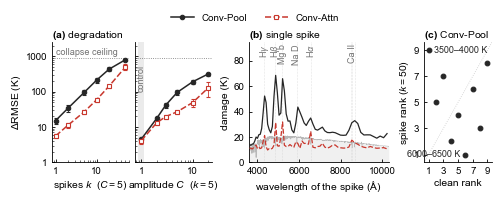

In [3]:
deg_k = pd.read_csv(os.path.join(RESULTS_DIR, 'step51_degradation_density.csv'))
deg_c = pd.read_csv(os.path.join(RESULTS_DIR, 'step51_degradation_amplitude.csv'))
sus = pd.read_csv(os.path.join(RESULTS_DIR, 'step51_susceptibility.csv'))
clean = pd.read_csv(os.path.join(RESULTS_DIR, 'step50_baseline_metrics.csv'))

# mean spectrum for the underlay of (b): every tenth test spectrum is plenty for a shape
mean_flux = None
try:
    import h5py
    split = pd.read_csv(os.path.join(DATA_DIR, 'sdss_final_catalog.csv'),
                        usecols=['dataset_split'])['dataset_split'].to_numpy()
    rows = np.flatnonzero(split == 'test')[::10]
    with h5py.File(os.path.join(DATA_DIR, 'sdss_tensors.h5'), 'r') as f:
        mean_flux = np.asarray(f['X'][rows], dtype=np.float64).reshape(len(rows), -1).mean(axis=0)
    print(f'mean spectrum from {len(rows):,} test spectra')
except (ImportError, OSError, KeyError) as e:
    print('mean spectrum unavailable, underlay skipped:', e)

# layout in cm: 12.2 wide; 0.8 below for x labels, 0.85 above for titles and legend
fig = plt.figure(figsize=(TEXTWIDTH, 4.7 * CM))
Y0, H = 0.80, 3.05
a1 = axes_cm(fig, 0.95, Y0, 1.95, H)
a2 = axes_cm(fig, 3.05, Y0, 1.95, H, sharey=a1)
ax_b = axes_cm(fig, 5.95, Y0, 3.55, H)
ax_c = axes_cm(fig, 10.40, Y0, 1.72, H)

# (a) density and amplitude sweeps, mean over seeds with the seed sd as error bars
for ax, df, lev, xlab in ((a1, deg_k, 'k', r'spikes $k$  ($C = 5$)'),
                          (a2, deg_c, 'C', r'amplitude $C$  ($k = 5$)')):
    df = df[df.regime == 'all']
    for m in MODELS:
        g = df[df.model == m].groupby(lev)['d_rmse_K']
        line(ax, g.mean().index, g.mean().values, m, yerr=g.std().values, zorder=3)
    ax.axhline(CEILING_K, color=GUIDE, lw=0.6, ls=':', zorder=1)
    ax.set_xscale('log')
    ax.set_xlabel(xlab)
a1.set_yscale('log')
a1.set_ylim(1, 2500)
plain_log(a1, 'y')
for ax in (a1, a2):
    plain_log(ax, 'x')
a1.set_ylabel(r'$\Delta$RMSE (K)')
a1.text(1.0, CEILING_K * 1.12, 'collapse ceiling', color=GUIDE, fontsize=ANNO,
        ha='left', va='bottom')
plt.setp(a2.get_yticklabels(), visible=False)
a2.axvspan(0.88, 1.14, color=SHADE, lw=0, zorder=0)
a2.text(1.0, 600, 'control', color=GUIDE, fontsize=ANNO, ha='center', va='top',
        rotation=90)
title(a1, 'a', 'degradation')

# (b) single-spike damage by landing wavelength
sus = sus.assign(lam=np.interp(sus['pixel'], np.arange(GRID_N), WAVE))
top = 0.0
for m in MODELS:
    g = sus[sus.model == m].groupby('lam')['damage_median'].mean()
    line(ax_b, g.index, g.values, m, markers=False, lw=0.9, zorder=3)
    top = max(top, g.max())
ax_b.set_ylim(0, top * 1.38)
if mean_flux is not None:
    shape = mean_flux / np.percentile(mean_flux, 99.5) * 0.30 * top
    ax_b.fill_between(WAVE, 0, shape, color='0.94', lw=0, zorder=0)
    ax_b.plot(WAVE, shape, color='0.72', lw=0.35, zorder=1)
for name, lams in {r'H$\gamma$': [4340.5], r'H$\beta$': [4861.3], 'Mg b': [5183.6],
                   'Na D': [5892.9], r'H$\alpha$': [6562.8],
                   'Ca II': [8498.0, 8542.1, 8662.1]}.items():
    for lam in lams:
        ax_b.axvline(lam, color='0.8', lw=0.4, ls=':', zorder=1)
    ax_b.text(np.mean(lams), top * 1.36, name, rotation=90, ha='center', va='top',
              fontsize=ANNO, color=GUIDE)
ax_b.set_xlim(WAVE[0], WAVE[-1])
ax_b.set_xlabel(r'wavelength of the spike (${\rm \AA}$)')
ax_b.set_ylabel('damage (K)')
title(ax_b, 'b', 'single spike')

# (c) clean rank against spike rank, Conv-Pool
cr = (clean[(clean.model == POOL) & (clean.regime != 'all')]
      .groupby('regime')['rmse_K'].mean())
ar = (deg_k[(deg_k.model == POOL) & (deg_k.regime != 'all') & (deg_k.k == 50)]
      .groupby('regime')['d_rmse_K'].mean())
regs = [r for r in regime_order(cr.index) if r in ar.index]
rc, ra = cr[regs].rank(), ar[regs].rank()
ax_c.plot([0.4, len(regs) + 0.6], [0.4, len(regs) + 0.6], color='0.8', lw=0.6, ls=':',
          zorder=1)
ax_c.plot(rc.values, ra.values, ls='none', marker='o', ms=3.4, color=INK, zorder=3)
# label the most accurate regime on its right and the least damaged on its left
for r, dx, ha in ((rc.idxmin(), 4, 'left'), (ra.idxmin(), -4, 'right')):
    lo, hi = (int(float(v)) for v in r.strip('(] ').split(','))
    ax_c.annotate(f'{lo}–{hi} K', (rc[r], ra[r]), xytext=(dx, 0),
                  textcoords='offset points', fontsize=ANNO, ha=ha, va='center',
                  color=INK)
ticks = [1, 3, 5, 7, 9][:len(regs)]
ax_c.set_xticks(ticks); ax_c.set_yticks(ticks)
ax_c.set_xlim(0.4, len(regs) + 0.6); ax_c.set_ylim(0.4, len(regs) + 0.6)
ax_c.set_xlabel('clean rank')
ax_c.set_ylabel(r'spike rank ($k = 50$)')
title(ax_c, 'c', 'Conv-Pool')

model_legend(fig)
save(fig, 'fig2_spikes.pdf')
plt.show()

## Fig. 3: global distortions

**(a)** Degradation against effective resolving power, axis reversed, with the collapse ceiling, the training resolution and the $R \approx 1500$ threshold marked. **(b)** Degradation across the nine temperature regimes at $\sigma = 2$ ($R_{\rm eff} \approx 764$), mean over seeds with the seed standard deviation. **(c)** Signed bias against colour excess, de-reddening to the left of zero and reddening to the right, with the $\pm 47.9$ K label-noise floor shaded and disc extinction $E(B-V) \approx 0.2$ marked. **(d)** The full extinction law against its linearisation (dotted) at identical colour excess.

Laid out 2 × 2 at 12.2 × 7.45 cm; four panels in one row would leave each about 2.5 cm wide, too narrow for the regime panel. Change `FIG3_SIZE` if the page budget needs it.

[saved] figures\fig3_global.pdf


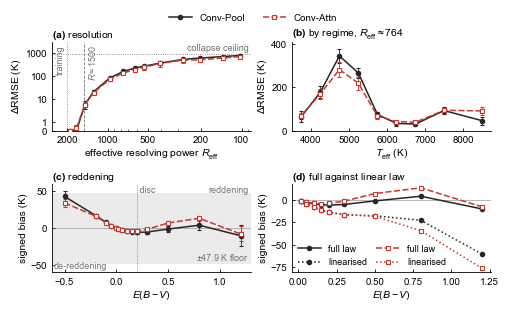

In [4]:
FIG3_SIZE = (TEXTWIDTH, 7.45 * CM)

deg54 = pd.read_csv(os.path.join(RESULTS_DIR, 'step54_degradation.csv'))
deg55 = pd.read_csv(os.path.join(RESULTS_DIR, 'step55_degradation.csv'))
first = pd.read_csv(os.path.join(RESULTS_DIR, 'step55_first_order_control.csv'))

blur = deg54[deg54.sweep == 'A']
if 'renormalised' in blur.columns:
    blur = blur[blur.renormalised.astype(str).str.lower().isin(['true', '1'])]

# layout in cm: two columns of 5.05, two rows of 2.25, room for labels and the legend
fig = plt.figure(figsize=FIG3_SIZE)
W_AX, H_AX = 5.05, 2.25
ax_a = axes_cm(fig, 1.00, 4.35, W_AX, H_AX)
ax_b = axes_cm(fig, 7.10, 4.35, W_AX, H_AX)
ax_c = axes_cm(fig, 1.00, 0.75, W_AX, H_AX)
ax_d = axes_cm(fig, 7.10, 0.75, W_AX, H_AX)

# (a) degradation against resolving power
ov = blur[blur.regime == 'all']
for m in MODELS:
    g = ov[ov.model == m].groupby('r_eff')['d_rmse_K']
    line(ax_a, g.mean().index, g.mean().values, m, yerr=g.std().values, zorder=3)
ax_a.axhline(CEILING_K, color=GUIDE, lw=0.6, ls=':', zorder=1)
ax_a.set_xscale('log')
ax_a.set_yscale('symlog', linthresh=1, linscale=0.35)
ax_a.set_ylim(0, 3000)
ax_a.yaxis.set_major_locator(FixedLocator([0, 1, 10, 100, 1000]))
ax_a.yaxis.set_major_formatter(FixedFormatter(['0', '1', '10', '100', '1000']))
ax_a.set_xlim(2600, 85)                 # reversed: resolution falls to the right
ax_a.xaxis.set_major_locator(FixedLocator([2000, 1000, 500, 200, 100]))
ax_a.xaxis.set_major_formatter(FixedFormatter(['2000', '1000', '500', '200', '100']))
# the axis is reversed: the training label sits left of its line, the threshold right
for r0, xl, lab in ((2000, 2000 * 1.13, 'training'), (1500, 1500 * 0.87, r'$R \approx 1500$')):
    ax_a.axvline(r0, color=GUIDE, lw=0.6, ls='--' if r0 == 1500 else ':', zorder=1)
    ax_a.text(xl, 0.97, lab, transform=ax_a.get_xaxis_transform(), rotation=90,
              ha='center', va='top', fontsize=ANNO, color=GUIDE)
ax_a.text(0.99, CEILING_K * 1.15, 'collapse ceiling', transform=ax_a.get_yaxis_transform(),
          ha='right', va='bottom', fontsize=ANNO, color=GUIDE)
ax_a.xaxis.set_minor_formatter(NullFormatter())
ax_a.set_xlabel(r'effective resolving power $R_{\rm eff}$')
ax_a.set_ylabel(r'$\Delta$RMSE (K)')
title(ax_a, 'a', 'resolution')

# (b) by temperature regime at sigma = 2, mean over seeds with the seed sd
byreg = blur[blur.regime != 'all']
regs = regime_order(byreg.regime.unique())
cen = np.array([regime_centre(r) for r in regs])
ref = byreg[np.isclose(byreg.sigma, 2.0)]
top_b = 0.0
for m in MODELS:
    g = ref[ref.model == m].groupby('regime')['d_rmse_K']
    mu, sd = g.mean().reindex(regs), g.std().reindex(regs)
    line(ax_b, cen, mu.values, m, yerr=sd.values, zorder=3)
    top_b = max(top_b, float(np.nanmax(mu.values + sd.values)))
r_ref = float(ref.r_eff.mean())
ax_b.set_ylim(0, top_b * 1.08)
ax_b.set_xticks([4000, 5000, 6000, 7000, 8000])
ax_b.set_xlabel(r'$T_{\rm eff}$ (K)')
ax_b.set_ylabel(r'$\Delta$RMSE (K)')
title(ax_b, 'b', rf'by regime, $R_{{\rm eff}} \approx {r_ref:.0f}$')

# (c) signed bias against signed colour excess: de-reddening < 0 < reddening
ax_c.axhspan(-NOISE_FLOOR, NOISE_FLOOR, color=SHADE, lw=0, zorder=0)
ax_c.axhline(0, color='0.6', lw=0.5, zorder=1)
ax_c.axvline(0.2, color=GUIDE, lw=0.6, ls=':', zorder=1)
sw = deg55[(deg55.sweep.isin(['A', 'C'])) & (deg55.regime == 'all')]
for m in MODELS:
    g = sw[sw.model == m].groupby('ebv')['d_bias_K']
    x = np.r_[0.0, g.mean().index.to_numpy()]            # zero colour excess, zero bias
    y = np.r_[0.0, g.mean().to_numpy()]
    e = np.r_[0.0, g.std().to_numpy()]
    o = np.argsort(x)
    line(ax_c, x[o], y[o], m, yerr=e[o], zorder=3)
ax_c.set_xlim(-0.62, 1.30)
lim = max(NOISE_FLOOR * 1.25, float(np.nanmax(np.abs(sw.groupby(['model', 'ebv'])
                                                    ['d_bias_K'].mean()))) * 1.3)
ax_c.set_ylim(-lim, lim)
ax_c.text(-0.60, -lim * 0.97, 'de-reddening', fontsize=ANNO, color=GUIDE, ha='left', va='bottom')
ax_c.text(1.28, lim * 0.97, 'reddening', fontsize=ANNO, color=GUIDE, ha='right', va='top')
ax_c.text(0.2, lim * 0.97, ' disc', fontsize=ANNO, color=GUIDE, ha='left', va='top')
ax_c.text(1.28, -NOISE_FLOOR * 0.97, rf'$\pm${NOISE_FLOOR:.1f} K floor', fontsize=ANNO,
          color=GUIDE, ha='right', va='bottom')
ax_c.set_xlabel(r'$E(B-V)$')
ax_c.set_ylabel('signed bias (K)')
title(ax_c, 'c', 'reddening')

# (d) full law against its linearisation; line style = law, colour and marker = model
ax_d.axhline(0, color='0.6', lw=0.5, zorder=1)
for m in MODELS:
    s = first[first.model == m].sort_values('ebv')
    line(ax_d, s.ebv, s.full_law_bias_K, m, zorder=3)
    line(ax_d, s.ebv, s.linear_law_bias_K, m, ls=':', zorder=3)
hd = []
for m in MODELS:
    base = {k: v for k, v in STYLE[m].items() if k != 'ls'}
    hd += [Line2D([], [], **base, ls=STYLE[m]['ls']), Line2D([], [], **base, ls=':')]
# two columns, one per model (colour and marker as in the figure legend), two rows,
# one per law: compact enough to stay clear of the curves in the lower-left corner
ax_d.legend(hd, ['full law', 'linearised', 'full law', 'linearised'], ncol=2,
            loc='lower left', fontsize=ANNO, handlelength=2.6, columnspacing=1.0)
ax_d.set_xlabel(r'$E(B-V)$')
ax_d.set_ylabel('signed bias (K)')
title(ax_d, 'd', 'full against linear law')

model_legend(fig)
save(fig, 'fig3_global.pdf')
plt.show()

## Check

All three files must exist after a full run.

In [5]:
for f in ('fig1_architecture.pdf', 'fig2_spikes.pdf', 'fig3_global.pdf'):
    p = os.path.join(OUT, f)
    print(f'{f:24s}', f'{os.path.getsize(p) / 1024:6.1f} KB' if os.path.exists(p) else 'MISSING')

fig1_architecture.pdf    MISSING
fig2_spikes.pdf           122.1 KB
fig3_global.pdf            60.2 KB
